# Coding Assignment 2

## What can a traveller learn from a year of flights?

A travel editor wants to know how often flights from New York arrived late in 2013. Give the editor a table they can check. Then pitch a question of your own and answer it with one figure the editor could publish.

**Individual take-home assignment**  100 marks · 10% of the course grade · about three hours. Use pandas and plotnine from the Day 2 environment.

Open your pull request by **Monday, 16 November 2026 at 23:59 Vilnius time**.

## Get the data

Download both files into a folder called `data` beside your notebook. Keep the original files so that someone can run your analysis again.

- [Download flights.csv.zip](https://raw.githubusercontent.com/machow/nycflights13-py/1d40369400d77379a78641afd119fc302a5a9659/nycflights13/data/flights.csv.zip) for 336,776 scheduled flight records from Newark (EWR), Kennedy (JFK) and LaGuardia (LGA) in 2013. Keep this file zipped.
- [Download airlines.csv](https://raw.githubusercontent.com/machow/nycflights13-py/1d40369400d77379a78641afd119fc302a5a9659/nycflights13/data/airlines.csv) to get the full airline `name` for each `carrier` code. If the CSV opens as text, save it as `airlines.csv`.

In [11]:
import pandas as pd

flights = pd.read_csv("data/flights.csv")
airlines = pd.read_csv("data/airlines.csv")


Departure and arrival delays are measured in minutes against the schedule. Negative values mean early and zero means on time. The `hour` column is the scheduled departure hour. The data come from the U.S. Bureau of Transportation Statistics via Hadley Wickham's *nycflights13* (CC0). Michael Chow provides the CSV files. See the [flight variable guide](https://nycflights13.tidyverse.org/reference/flights.html) and [airline lookup guide](https://nycflights13.tidyverse.org/reference/airlines.html).

## 1. Build the analysis sample [20 marks]

### (a) [8 marks]
State what one row represents in each file. Show both shapes, check the type of `arr_delay`, and count exact duplicate flight rows across all original columns. Explain whether any rows need removing. An airline flight number can recur on different dates.

**Answer.** One row in `flights` represents one scheduled flight record on a particular date, identified by its date, carrier, and flight number (among other fields). One row in `airlines` represents one carrier code and its airline name. The files have 336,776 rows × 19 columns and 16 rows × 2 columns, respectively. `arr_delay` is `float64` because missing arrivals are represented as `NaN`. There are 0 exact duplicate flight rows across all original columns, so no rows need to be removed. A carrier flight number recurring on different dates is not an exact duplicate.

In [2]:
print("One row in flights: one scheduled flight record on a particular date.")
print("One row in airlines: one carrier code and its airline name.")
print("flights shape:", flights.shape)
print("airlines shape:", airlines.shape)
print("arr_delay dtype:", flights["arr_delay"].dtype)
print("Exact duplicate flight rows:", flights.duplicated().sum())

One row in flights: one scheduled flight record on a particular date.
One row in airlines: one carrier code and its airline name.
flights shape: (336776, 19)
airlines shape: (16, 2)
arr_delay dtype: float64
Exact duplicate flight rows: 0


### (b) [12 marks]
Show how many flight records have a known arrival delay and how many have a missing one. Check that the two counts add up to your flight total. Create a late-arrival indicator for delays of **15 minutes or more**. Keep the outcome missing when the delay is missing. Show how your rule handles an early arrival, 14 minutes, exactly 15 minutes and a missing value.


In [3]:
known_arrival_delays = flights["arr_delay"].notna().sum()
missing_arrival_delays = flights["arr_delay"].isna().sum()
print("Known arrival delays:", known_arrival_delays)
print("Missing arrival delays:", missing_arrival_delays)
print("Total flight records:", len(flights))
print("Counts sum to flight total:", known_arrival_delays + missing_arrival_delays == len(flights))

flights["late_arrival"] = flights["arr_delay"].ge(15).mask(flights["arr_delay"].isna(), pd.NA).astype("boolean")
examples = pd.Series([-5, 14, 15, float("nan")], index=["early arrival", "14 minutes", "exactly 15 minutes", "missing delay"], dtype="float64")
example_indicator = examples.ge(15).mask(examples.isna(), pd.NA).astype("boolean")
print("\nRule examples (arr_delay → late_arrival):")
for label, delay, outcome in zip(examples.index, examples, example_indicator):
    print(f"{label}: {delay} → {outcome}")

Known arrival delays: 327346
Missing arrival delays: 9430
Total flight records: 336776
Counts sum to flight total: True

Rule examples (arr_delay → late_arrival):
early arrival: -5.0 → False
14 minutes: 14.0 → False
exactly 15 minutes: 15.0 → True
missing delay: nan → <NA>




## 2. Attach the airline names [10 marks]

Join the lookup to the flight records using `carrier`. Check that each lookup code occurs once, validate the many-to-one join in pandas, and show the row counts before and after. Report how many flights have an unmatched code. Use the airline names in your table on the next page.
**Answer.** The 16 lookup carrier codes are unique. A left many-to-one merge keeps all 336,776 flight rows; the joined data also have 336,776 rows, and 0 flights have an unmatched carrier code.

In [4]:
print("Airline lookup rows:", len(airlines))
print("Unique carrier codes:", airlines["carrier"].nunique())
print("Duplicate lookup codes:", airlines["carrier"].duplicated().sum())

flights_with_airlines = flights.merge(
    airlines,
    on="carrier",
    how="left",
    validate="many_to_one",
    indicator=True,
)
print("Flight rows before join:", len(flights))
print("Flight rows after join:", len(flights_with_airlines))
print("Flights with unmatched code:", flights_with_airlines["_merge"].eq("left_only").sum())

Airline lookup rows: 16
Unique carrier codes: 16
Duplicate lookup codes: 0
Flight rows before join: 336776
Flight rows after join: 336776
Flights with unmatched code: 0


## 3. Give the editor a table they can check [30 marks]

### (a) [18 marks]
Identify the five busiest airlines by their number of scheduled flight records. Present one row per airline, busiest first, then a final row for **all airlines combined**, including those outside the top five. Show the airline name, scheduled flights, flights with a known arrival delay, late arrivals, and the percentage late among flights with a known arrival delay. Give columns reader-friendly headings and round only the displayed percentages to one decimal place.
**Answer.** The five busiest carriers by scheduled records are United, JetBlue, ExpressJet, Delta and American. The table reports each airline’s known-delay denominator and late-arrival count; the final row combines all airlines. Percentages are late arrivals divided by flights with a known arrival delay.

In [5]:
airline_counts = (
    flights_with_airlines
    .groupby(["carrier", "name"], as_index=False)
    .agg(
        scheduled_flights=("carrier", "size"),
        known_arrival_delays=("arr_delay", "count"),
        late_arrivals=("late_arrival", "sum"),
    )
)
airline_counts["percent_late"] = (
    airline_counts["late_arrivals"] / airline_counts["known_arrival_delays"] * 100
)
top_five = airline_counts.sort_values("scheduled_flights", ascending=False).head(5)
all_airlines = pd.DataFrame([{
    "carrier": "ALL",
    "name": "All airlines combined",
    "scheduled_flights": len(flights_with_airlines),
    "known_arrival_delays": flights_with_airlines["arr_delay"].count(),
    "late_arrivals": flights_with_airlines["late_arrival"].sum(),
}])
all_airlines["percent_late"] = (
    all_airlines["late_arrivals"] / all_airlines["known_arrival_delays"] * 100
)
summary = pd.concat([top_five, all_airlines], ignore_index=True)
summary_table = summary[[
    "name", "scheduled_flights", "known_arrival_delays", "late_arrivals", "percent_late"
]].rename(columns={
    "name": "Airline",
    "scheduled_flights": "Scheduled flights",
    "known_arrival_delays": "Known arrival delays",
    "late_arrivals": "Late arrivals (15+ min)",
    "percent_late": "Late among known delays (%)",
})
print(summary_table.to_string(index=False, formatters={"Late among known delays (%)": lambda value: f"{value:.1f}%"}))

                 Airline  Scheduled flights  Known arrival delays  Late arrivals (15+ min) Late among known delays (%)
   United Air Lines Inc.              58665                 57782                    13004                       22.5%
         JetBlue Airways              54635                 54049                    14567                       27.0%
ExpressJet Airlines Inc.              54173                 51108                    16399                       32.1%
    Delta Air Lines Inc.              48110                 47658                     9038                       19.0%
  American Airlines Inc.              32729                 31947                     6203                       19.4%
   All airlines combined             336776                327346                    80100                       24.5%


### (b) [6 marks]
Pick one of the five airlines. Filter its underlying flight records and recompute its numerator and denominator independently of the summary table. Show the arithmetic for that airline's percentage and check that it agrees with the table.
**Answer.** United is the busiest airline in this sample. Filtering its flight records independently gives 13,004 late arrivals among 57,782 flights with known arrival delays: 13,004 ÷ 57,782 × 100 = 22.5%. This matches the United percentage in the summary table.

In [6]:
selected_carrier = "UA"
united_flights = flights_with_airlines.loc[flights_with_airlines["carrier"].eq(selected_carrier)]
united_known = united_flights["arr_delay"].notna().sum()
united_late = united_flights["late_arrival"].sum()
united_percent = united_late / united_known * 100
summary_percent = summary.loc[summary["carrier"].eq(selected_carrier), "percent_late"].iloc[0]
print("Airline:", united_flights["name"].iloc[0])
print(f"Numerator (late arrivals): {united_late:,}")
print(f"Denominator (known arrival delays): {united_known:,}")
print(f"Calculation: {united_late:,} / {united_known:,} * 100 = {united_percent:.1f}%")
print("Agrees with summary table:", round(united_percent, 10) == round(summary_percent, 10))

Airline: United Air Lines Inc.
Numerator (late arrivals): 13,004
Denominator (known arrival delays): 57,782
Calculation: 13,004 / 57,782 * 100 = 22.5%
Agrees with summary table: True


### (c) [6 marks]
Suppose the editor divides the total number of known late arrivals by **all scheduled flights**. Calculate this alternative for the all-airlines row. Report how much it changes the headline rate in percentage points and explain what the alternative denominator counts.
**Answer.** Using all scheduled flights as the denominator gives 80,100 ÷ 336,776 × 100 = 23.8%, about 0.7 percentage points lower than the 24.5% headline rate. This alternative denominator includes scheduled records whose arrival delay is missing, while its numerator includes only known late arrivals.

In [7]:
known_late_total = flights_with_airlines["late_arrival"].sum()
known_delay_total = flights_with_airlines["arr_delay"].count()
scheduled_total = len(flights_with_airlines)
headline_rate = known_late_total / known_delay_total * 100
all_scheduled_rate = known_late_total / scheduled_total * 100
change_pp = all_scheduled_rate - headline_rate
print(f"Known late arrivals: {known_late_total:,}")
print(f"All scheduled flights: {scheduled_total:,}")
print(f"Headline rate (known-delay denominator): {headline_rate:.1f}%")
print(f"Alternative rate (all scheduled flights): {all_scheduled_rate:.1f}%")
print(f"Change: {change_pp:.2f} percentage points")

Known late arrivals: 80,100
All scheduled flights: 336,776
Headline rate (known-delay denominator): 24.5%
Alternative rate (all scheduled flights): 23.8%
Change: -0.69 percentage points


## 4. Pitch and illustrate your own finding [40 marks]

Choose a reader and a question you can answer from these records. Go beyond redrawing the five-airline table. For example, how does the chance of a late arrival change from morning to evening at each airport? How often does a flight that leaves at least 15 minutes late still arrive by its scheduled time? You may pursue a different question.

### (a) The pitch [8 marks]
Name your reader and the comparison they care about. Define the measure, the flights you include and any cutoffs you choose. Give the number of flights behind the figure.
**Pitch.** My reader is a traveler whose flight is already running late. I compare the share of flights from EWR, JFK and LGA that still arrive on schedule or early, among records with a departure delay of at least 15 minutes and a known arrival delay. The analysis includes 72,420 flights in 2013; the measure is flights with `arr_delay <= 0` divided by included flights.

In [8]:
late_departure_flights = flights_with_airlines.loc[
    flights_with_airlines["dep_delay"].ge(15)
    & flights_with_airlines["arr_delay"].notna()
].copy()
late_departure_flights["arrived_by_schedule"] = late_departure_flights["arr_delay"].le(0)
airport_summary = (
    late_departure_flights
    .groupby("origin", as_index=False)
    .agg(
        flights=("origin", "size"),
        arrived_by_schedule=("arrived_by_schedule", "sum"),
    )
)
airport_summary["percent_by_schedule"] = (
    airport_summary["arrived_by_schedule"] / airport_summary["flights"] * 100
)
airport_summary["label"] = airport_summary["percent_by_schedule"].map(lambda value: f"{value:.1f}%")
print("Flights included:", len(late_departure_flights))
print(airport_summary.sort_values("percent_by_schedule", ascending=False).to_string(index=False, formatters={"percent_by_schedule": lambda value: f"{value:.1f}%"}))

Flights included: 72420
origin  flights  arrived_by_schedule percent_by_schedule label
   JFK    23209                 2005                8.6%  8.6%
   EWR    29547                 1854                6.3%  6.3%
   LGA    19664                 1110                5.6%  5.6%


### (b) The figure [14 marks]
Make one figure in plotnine. Choose the geometry, variables, grouping and scale that bring out your comparison. Give it a headline supported by the data, label the units and make the groups easy to distinguish at the size a reader will see.
The first version uses bars to show the percentage of qualifying flights arriving by schedule at each airport. The groups are airports; the x variable is airport and the y variable is the percentage. The figure below compares the 2013 records.

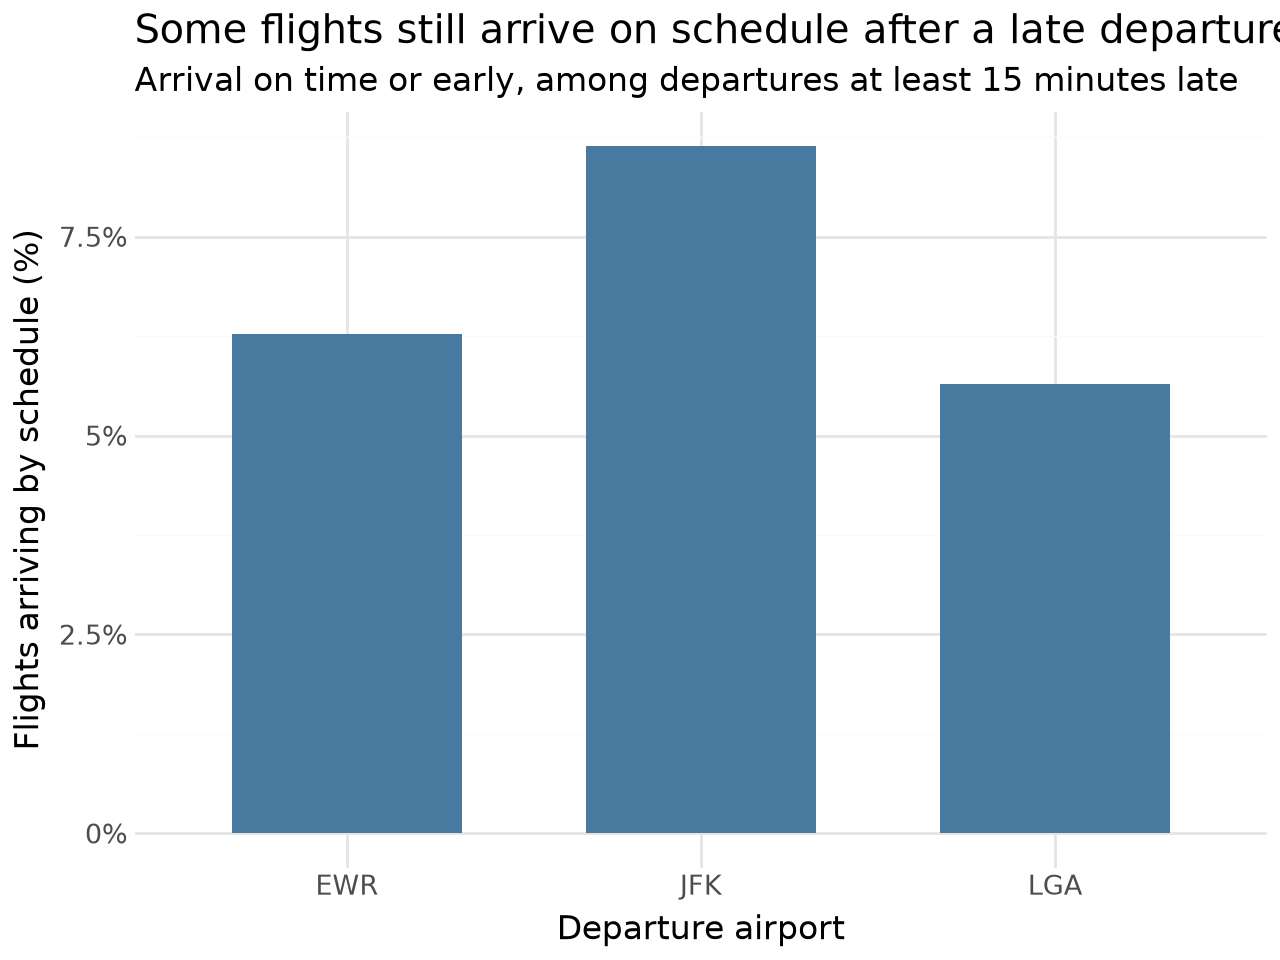

In [9]:
from plotnine import aes, geom_col, ggplot, labs, scale_y_continuous, theme_minimal

first_version = (
    ggplot(airport_summary, aes(x="origin", y="percent_by_schedule"))
    + geom_col(fill="#477A9E", width=0.65)
    + scale_y_continuous(labels=lambda values: [f"{value:g}%" for value in values])
    + labs(
        title="Some flights still arrive on schedule after a late departure",
        subtitle="Arrival on time or early, among departures at least 15 minutes late",
        x="Departure airport",
        y="Flights arriving by schedule (%)",
    )
    + theme_minimal(base_size=12)
)
first_version

### (c) The edit [8 marks]
Keep a first version in the notebook. Change one design decision that affects how a reader sees the evidence. Show the final version and explain in two sentences what is easier to see and what detail, if any, is lost. A simple figure can earn full marks.
**Edit.** The final dot plot puts the airport percentages on one horizontal scale, making the gaps between airports easier to compare. Additionally, we now see the exact percentages. It gives up the bars’ visual emphasis on each percentage’s magnitude from a zero baseline.

C:\Users\asefl\miniforge3\envs\research-methods\Lib\site-packages\plotnine\ggplot.py:623: PlotnineWarning: Saving 8 x 4.8 in image.
C:\Users\asefl\miniforge3\envs\research-methods\Lib\site-packages\plotnine\ggplot.py:624: PlotnineWarning: Filename: figure.png


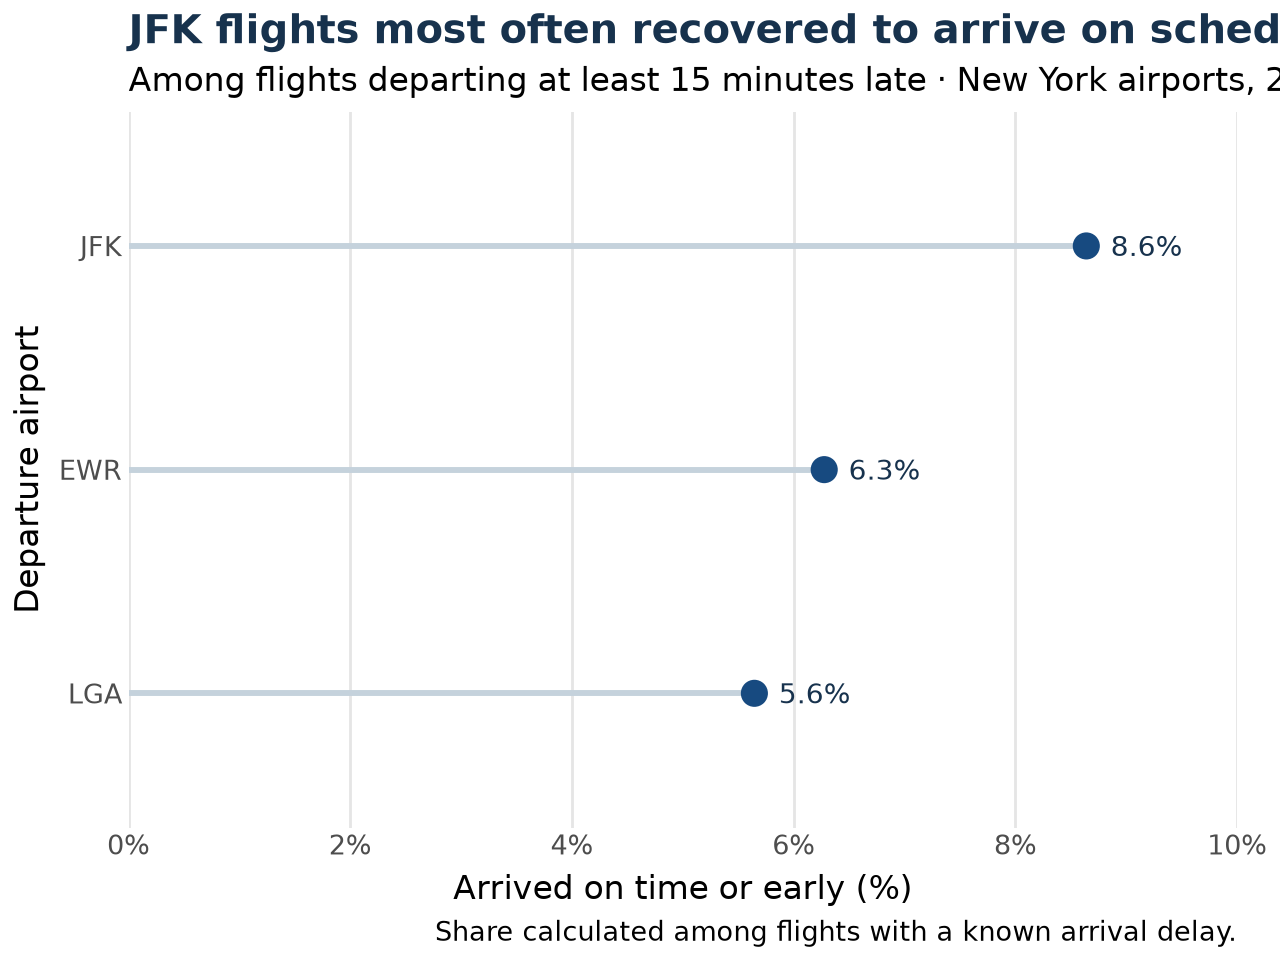

In [10]:
from plotnine import element_blank, element_text, geom_point, geom_segment, geom_text, scale_x_continuous, scale_y_discrete, theme

airport_order = airport_summary.sort_values("percent_by_schedule", ascending=True)["origin"].tolist()
airport_summary["origin"] = pd.Categorical(airport_summary["origin"], categories=airport_order, ordered=True)
final_figure = (
    ggplot(airport_summary, aes(y="origin", x="percent_by_schedule"))
    + geom_segment(aes(x=0, xend="percent_by_schedule", y="origin", yend="origin"), color="#C5D2DC", size=1.2)
    + geom_point(color="#174A80", size=4.5)
    + geom_text(aes(label="label"), nudge_x=0.22, ha="left", size=10, color="#17324D")
    + scale_x_continuous(
        limits=(0, 10),
        breaks=[0, 2, 4, 6, 8, 10],
        labels=lambda values: [f"{value:g}%" for value in values],
        expand=(0, 0),
    )
    + scale_y_discrete(limits=airport_order)
    + labs(
        title="JFK flights most often recovered to arrive on schedule",
        subtitle="Among flights departing at least 15 minutes late · New York airports, 2013",
        x="Arrived on time or early (%)",
        y="Departure airport",
        caption="Share calculated among flights with a known arrival delay.",
    )
    + theme_minimal(base_size=12)
    + theme(
        plot_title=element_text(weight="bold", color="#17324D"),
        panel_grid_major_y=element_blank(),
        panel_grid_minor=element_blank(),
    )
)
final_figure.save("figure.png", width=8, height=4.8, dpi=180)
final_figure

### (d) The caption [10 marks]
In 60–100 words, answer your question with a numerical comparison calculated in the notebook. Name the source, period and one specific limit on what the comparison can establish.
**Caption.** For flights that left at least 15 minutes late, 2,005 of 23,209 JFK flights (8.6%) still arrived on schedule or early. The share was 1,854 of 29,547 (6.3%) at EWR and 1,110 of 19,664 (5.6%) at LGA. This comparison uses 72,420 scheduled flight records from EWR, JFK and LGA during 2013, based on U.S. Bureau of Transportation Statistics data distributed through *nycflights13*. It is descriptive: differences may reflect routes, airlines, schedules, weather and other factors, so the rates do not show that an airport caused the outcome.

## What to submit

Open a pull request to `main` from your own branch. In `submissions/exercise-02/YOUR-USERNAME/`, include `exercise_02.ipynb` with the table, figure drafts and caption, the final `figure.png`, and a short `README.md` with the download and run instructions. Keep the two raw downloads on your computer. Restart the kernel and run all cells in order to check that the notebook recreates the table and saves the final figure.